### PDE-FIND for Schrodinger

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import scipy.io as sio
import algorithms
import utils
import importlib

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          
plt.rcParams['font.serif'] = ['Computer Modern Serif']  
importlib.reload(algorithms) 
importlib.reload(utils)

<module 'utils' from '/home/s2421480/Documents/PhD_thesis/experiments/chapter2/utils.py'>

In [2]:
# Importing the data

data = sio.loadmat('./data/nls.mat')
u = data['usol']
x = data['x'][0]
t = data['t'][:, 0]
dt = t[1]-t[0]
dx = x[2]-x[1]

In [7]:
u.shape

(501, 512)

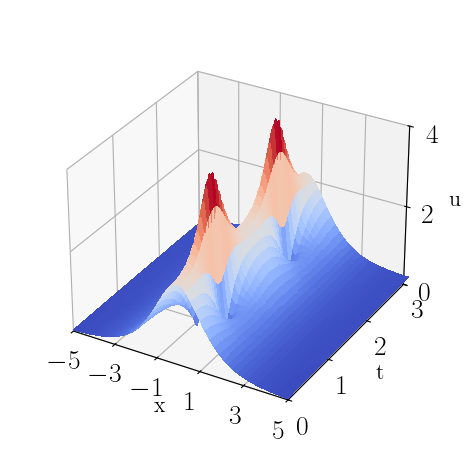

In [ ]:
X, T = np.meshgrid(x, t)

xticks = np.arange(-5, 6, 2)
yticks = np.arange(0, 4, 1)
zticks = np.arange(0, 5, 2)
with utils.nice_3d_plot(xticks=xticks, yticks=yticks, zticks=zticks) as (fig, ax):
    ax.plot_surface(X, T, abs(u), cmap=plt.cm.coolwarm,
    linewidth=0, antialiased=False)
    #plt.title('Nonlinear Schrodinger Equation', fontsize = 20)
    ax.set_box_aspect(None, zoom=0.85)
    plt.tight_layout()
    ax.set_xlabel('x', fontsize = 16)
    ax.set_ylabel('t', fontsize = 16)
    ax.set_zlabel('u', fontsize = 16)
    #fig.savefig('./figures/nls_equation.pdf', bbox_inches="tight", dpi=300)


In [3]:
Ut, R, rhs_des = algorithms.build_linear_system(u.T, dt, dx, D=2, P=2)
['1'] + rhs_des[1:]

['1',
 'u',
 'u^2',
 'u_{x}',
 'uu_{x}',
 'u^2u_{x}',
 'u_{xx}',
 'uu_{xx}',
 'u^2u_{xx}']

In [4]:
## append the extra term present in the PDE 

new_col = ((np.abs(R[:, 1]) ** 2) * R[:, 1]).reshape(-1, 1)

# Append the new row to R
R = np.hstack((R, new_col))
rhs_des.append('|u|^2u')

In [7]:
w_best = algorithms.sindy_pde(R, Ut, 0.0005)
algorithms.print_pde(w_best, rhs_des)

u_t = (-0.000821 +0.499361i)u_{xx}
    + (0.001090 +1.005981i)|u|^2u
   


In [22]:
w_best

array([[ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [-0.00076719+0.50054007j],
       [ 0.        +0.j        ],
       [ 0.        +0.j        ],
       [ 0.00120589+1.00763956j]])

In [ ]:
xticks = np.arange(-5, 6, 2)
yticks = np.arange(0, 4, 1)
zticks = np.arange(0, 5, 2)
with utils.nice_3d_plot(xticks=xticks, yticks=yticks, zticks=zticks) as (fig, ax):
    ax.plot_surface(X, T, abs(u), rstride=1, cstride=1, cmap=plt.cm.coolwarm,
    linewidth=0, antialiased=False)
    plt.title('Nonlinear Schrodinger Equation', fontsize = 20)
    ax.set_xlabel('x', fontsize = 16)
    ax.set_ylabel('t', fontsize = 16)
    ax.set_zlabel('u', fontsize = 16)